# Jaccard similarity

Similarity between the *math*, *anxiety* and *exam* semantic frames within and across groups
(human vs GPT-OSS), via permutation and bootstrap tests, plus the comparison plots. Reads the
behavioural forma-mentis edge lists from `all_bfmns.pkl`.

In [1]:
import pickle
import numpy as np
import pandas as pd
import networkx as nx

from config import RESSERENO_ROOT
from jaccard_similarity_bfmn import (
    results_jaccard_similarities,
    plot_comparison,
    jaccard_similarity,
    get_sets_of_associations,
)

path_rassereno_analysis = RESSERENO_ROOT / "out" / "analysis"

In [2]:
# features_df = pd.read_json('/Users/emma/projects/cognoscolab/rassereno/notebooks/all_fmnts.json')
with open(f"{path_rassereno_analysis}/all_bfmns.pkl", "rb") as f:
    features = pickle.load(f)

In [3]:
def pooled_graph(participants):
    """participants: list of edge-lists (one per participant)"""
    G = nx.Graph()
    for edges in participants:
        G.add_edges_from(edges)
    return G


def jaccard_between(G, node1, node2):
    if node1 not in G or node2 not in G:
        return 0.0
    n1 = set(G.neighbors(node1))
    n2 = set(G.neighbors(node2))
    if not n1 and not n2:
        return 0.0
    return len(n1 & n2) / len(n1 | n2)


def bootstrap_group_J(participants, node1, node2, n_boot=5000):
    n = len(participants)
    boot_Js = np.empty(n_boot)
    for b in range(n_boot):
        sample_idx = np.random.randint(0, n, size=n)  # resample w/ replacement
        sample = [participants[i] for i in sample_idx]
        G = pooled_graph(sample)
        boot_Js[b] = jaccard_between(G, node1, node2)
    return boot_Js


def bootstrap_group_diff(
    participants_A, participants_B, node1, node2, n_boot=10000, ci=95
):
    """
    Returns a dict with:
      - observed J for A and B (using the full samples, not resampled)
      - bootstrap distributions for A, B and the difference (A - B)
      - percentile CI on the difference
      - two-sided bootstrap p-value for H0: J_A == J_B
    """
    # Observed values on the full (non-resampled) data
    obs_J_A = jaccard_between(pooled_graph(participants_A), node1, node2)
    obs_J_B = jaccard_between(pooled_graph(participants_B), node1, node2)
    obs_diff = obs_J_A - obs_J_B

    boot_A = bootstrap_group_J(participants_A, node1, node2, n_boot)
    boot_B = bootstrap_group_J(participants_B, node1, node2, n_boot)
    boot_diff = boot_A - boot_B  # paired by bootstrap iteration index

    lo = (100 - ci) / 2
    hi = 100 - lo
    ci_lo, ci_hi = np.percentile(boot_diff, [lo, hi])

    # Two-sided bootstrap p-value:
    # proportion of bootstrap diffs that cross zero relative to the observed sign
    p_one_sided = np.mean(boot_diff <= 0) if obs_diff > 0 else np.mean(boot_diff >= 0)
    p_two_sided = min(1.0, 2 * p_one_sided)

    return {
        "obs_J_A": obs_J_A,
        "obs_J_B": obs_J_B,
        "obs_diff": obs_diff,
        "boot_A": boot_A,
        "boot_B": boot_B,
        "boot_diff": boot_diff,
        "ci_lo": ci_lo,
        "ci_hi": ci_hi,
        "p_value": p_two_sided,
    }

In [4]:
comparisons = [
    ("psychology_high_anx", "gpt_oss_psychology_high_anx", "esame", "ansia"),
    ("psychology_low_anx", "gpt_oss_psychology_low_anx", "esame", "ansia"),
    ("high_school_high_anx", "gpt_oss_high_school_high_anx", "esame", "ansia"),
    ("high_school_low_anx", "gpt_oss_high_school_low_anx", "esame", "ansia"),
    ("physics_high_anx", "gpt_oss_physics", "esame", "ansia"),
    ("physics_low_anx", "gpt_oss_physics", "esame", "ansia"),
]

for group_a, group_b, w1, w2 in comparisons:
    res = bootstrap_group_diff(
        features[group_a], features[group_b], w1, w2, n_boot=5000
    )
    print(
        group_a,
        "vs",
        group_b,
        f"ΔJ={res['obs_diff']:.3f}",
        f"95% CI=[{res['ci_lo']:.3f}, {res['ci_hi']:.3f}]",
        f"p={res['p_value']:.4f}",
    )

psychology_high_anx vs gpt_oss_psychology_high_anx ΔJ=0.118 95% CI=[0.044, 0.227] p=0.0080
psychology_low_anx vs gpt_oss_psychology_low_anx ΔJ=0.013 95% CI=[-0.112, 0.047] p=0.6976
high_school_high_anx vs gpt_oss_high_school_high_anx ΔJ=0.090 95% CI=[0.090, 0.146] p=0.0000
high_school_low_anx vs gpt_oss_high_school_low_anx ΔJ=0.057 95% CI=[0.014, 0.108] p=0.0248
physics vs gpt_oss_physics ΔJ=0.079 95% CI=[0.062, 0.179] p=0.0244


## Humans: *exam* vs *anxiety*

Jaccard similarity between the *esame* and *ansia* frames of each human sample (same measure as
`comparison_3` below), computed without the GPT-oss samples while those are being regenerated.

In [3]:
HUMAN_GROUPS = [
    "high_school_high_anx",
    "high_school_low_anx",
    "physics_high_anx",
    "physics_low_anx",
    "psychology_high_anx",
    "psychology_low_anx",
]

human_exam_anxiety = {}
for group in HUMAN_GROUPS:
    anxiety_words, _, exam_words = get_sets_of_associations(features[group])
    human_exam_anxiety[group] = jaccard_similarity(exam_words, anxiety_words)

human_exam_anxiety = pd.Series(human_exam_anxiety, name="J(esame, ansia)").round(3)
human_exam_anxiety.to_csv(path_rassereno_analysis / "jaccard_exam_anxiety_humans.csv")
human_exam_anxiety

high_school_high_anx    0.079
high_school_low_anx     0.089
physics_high_anx        0.039
physics_low_anx         0.093
psychology_high_anx     0.055
psychology_low_anx      0.114
Name: J(esame, ansia), dtype: float64

## Psychology students

In [5]:
low_anx_psychology = results_jaccard_similarities(
    features, "gpt_oss_psychology_low_anx", "psychology_low_anx"
)

gpt_oss_psychology_low_anx:
matematica - ansia: 0.0136986301369863
matematica - esame: 0.03278688524590164
esame - ansia: 0.03508771929824561

psychology_low_anx:
matematica - ansia: 0.03731343283582089
matematica - esame: 0.07079646017699115
esame - ansia: 0.15315315315315314


In [6]:
high_anx_psychology = results_jaccard_similarities(
    features, "gpt_oss_psychology_high_anx", "psychology_high_anx"
)

gpt_oss_psychology_high_anx:
matematica - ansia: 0.014925373134328358
matematica - esame: 0.03571428571428571
esame - ansia: 0.038461538461538464

psychology_high_anx:
matematica - ansia: 0.12837837837837837
matematica - esame: 0.10810810810810811
esame - ansia: 0.13385826771653545


## High school students 2025

In [7]:
low_anx_high_school = results_jaccard_similarities(
    features, "gpt_oss_high_school_low_anx", "high_school_low_anx"
)

gpt_oss_high_school_low_anx:
matematica - ansia: 0.0
matematica - esame: 0.0
esame - ansia: 0.0

high_school_low_anx:
matematica - ansia: 0.04
matematica - esame: 0.054945054945054944
esame - ansia: 0.08860759493670886


In [8]:
high_anx_high_school = results_jaccard_similarities(
    features, "gpt_oss_high_school_high_anx", "high_school_high_anx"
)

gpt_oss_high_school_high_anx:
matematica - ansia: 0.0
matematica - esame: 0.03225806451612903
esame - ansia: 0.0

high_school_high_anx:
matematica - ansia: 0.0546875
matematica - esame: 0.07407407407407407
esame - ansia: 0.07920792079207921


## Fisica

In [9]:
physics_high_anx = results_jaccard_similarities(
    features, "gpt_oss_physics", "physics_high_anx"
)
physics_low_anx = results_jaccard_similarities(
    features, "gpt_oss_physics", "physics_low_anx"
)

gpt_oss_physics:
matematica - ansia: 0.0
matematica - esame: 0.0
esame - ansia: 0.0

physics:
matematica - ansia: 0.0707070707070707
matematica - esame: 0.056818181818181816
esame - ansia: 0.13793103448275862


## Plots

In [10]:
all_results = {
    **low_anx_psychology,
    **high_anx_psychology,
    **low_anx_high_school,
    **high_anx_high_school,
    **physics_high_anx,
    **physics_low_anx,
}

In [11]:
rows = []
for k, (v1, v2, v3) in all_results.items():
    source = "GPT-oss" if "gpt" in k else "Humans"
    group = k.replace("gpt_oss_", "").replace("_", " ").title()
    rows.append(
        {
            "group": group,
            "source": source,
            "comparison_1": v1,
            "comparison_2": v2,
            "comparison_3": v3,
        }
    )

similarities = pd.DataFrame(rows).sort_values("group")
for col in ["comparison_1", "comparison_2", "comparison_3"]:
    for idx in range(len(similarities[col])):
        if similarities.loc[idx, col] == 0:
            similarities.loc[idx, col] = 0.001

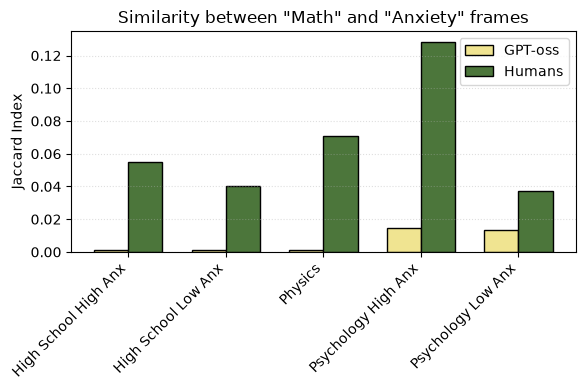

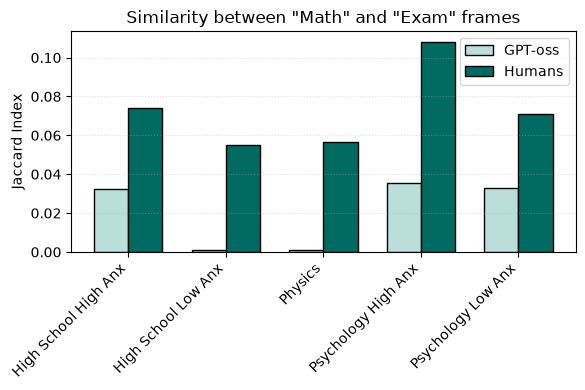

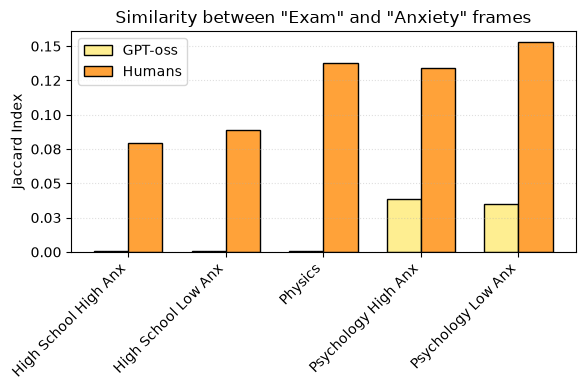

In [12]:
plot_comparison(
    similarities,
    "comparison_1",
    'Similarity between "Math" and "Anxiety" frames',
    "#F0E491",
    "#4C763B",
    path_rassereno_analysis,
)
plot_comparison(
    similarities,
    "comparison_2",
    'Similarity between "Math" and "Exam" frames',
    "#BADFDB",
    "#016B61",
    path_rassereno_analysis,
)
plot_comparison(
    similarities,
    "comparison_3",
    'Similarity between "Exam" and "Anxiety" frames',
    "#FEEE91",
    "#FFA239",
    path_rassereno_analysis,
)